In [1]:
import sys; sys.path.append("..")
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from db import engine
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
print("Connected")

Connected


In [2]:
a = pd.read_sql("SELECT name, value FROM raw.assumptions", engine)
A = dict(zip(a["name"], a["value"].astype(float)))

PRODUCTIVE = A["paid_hours_per_week"] * (1 - A["shrinkage"])
WEEKLY_ATTRITION = 1 - (1 - A["attrition_monthly"]) ** (12 / 52)
HIRE_LAG = int(A["time_to_hire_weeks"])
HORIZON = 26

print("Productive hours per FTE:", PRODUCTIVE)
print("Weekly attrition rate:", round(WEEKLY_ATTRITION, 4))
print("Hiring lag (weeks):", HIRE_LAG)

Productive hours per FTE: 29.25
Weekly attrition rate: 0.0047
Hiring lag (weeks): 4


In [3]:
forecast = pd.read_sql("SELECT * FROM cap.forecast", engine, parse_dates=["week_start"])

handle = pd.read_sql("SELECT * FROM clean.handle_time", engine)
handle["minutes"] = handle["minutes"].astype(float)

ledger = pd.read_sql("SELECT * FROM cap.ledger", engine, parse_dates=["week_start"])
last_actual = ledger["week_start"].max()
backlog_now = ledger[ledger["week_start"] == last_actual].set_index("team")["backlog_hours"].to_dict()

roster = pd.read_sql("SELECT * FROM clean.roster", engine, parse_dates=["start_date", "end_date"])
roster["fte"] = roster["fte"].astype(float)
roster_now = roster[(roster["start_date"] <= last_actual) &
                    (roster["end_date"].isna() | (roster["end_date"] > last_actual))].copy()
roster_now["tenure_weeks"] = ((last_actual - roster_now["start_date"]).dt.days // 7).astype(int)
teams = sorted(roster_now["team"].unique())

print("Planning from week:", last_actual.date())
print("Backlog now (hours):", backlog_now)
roster_now.groupby("team").agg(agents=("agent_id", "count"), fte=("fte", "sum"))

Planning from week: 2026-10-26
Backlog now (hours): {'Legal & Insurance': 366.2, 'Patient Requests': 197.8, 'Payer Requests': 367.3}


,agents,fte
team,,
Legal & Insurance,31,31.0
Patient Requests,25,24.0
Payer Requests,15,14.5


In [4]:
LEVERS = {
    "volume_change_pct": 0.0, "volume_change_start": 6,
    "automation_pct": 0.0, "automation_start": 4, "bounce_rate": 0.20, "qa_minutes": 1.5,
    "attrition_multiplier": 1.0, "attrition_weeks": 13,
    "hiring_freeze_weeks": 0, "extra_hires": 0,
}

def team_demand(team, lv):
    minutes = handle[handle["team"] == team].pivot(index="request_type", columns="channel", values="minutes")
    f = forecast[forecast["request_type"].isin(minutes.index)].join(minutes, on="request_type")
    boost = np.where(f["week_no"] >= lv["volume_change_start"], 1 + lv["volume_change_pct"], 1.0)
    volume = f["volume"] * boost
    digital = volume * f["digital_share"]
    paper = volume - digital
    fax = paper * f["fax_share_of_paper"]
    mail = paper - fax
    automated = np.where(f["week_no"] >= lv["automation_start"], digital * lv["automation_pct"], 0.0)
    manual_digital = digital - automated + automated * lv["bounce_rate"]
    paper_minutes = fax * f["fax"] + mail * f["mail"]
    f["workload_hours"] = (manual_digital * f["digital"] + paper_minutes + automated * lv["qa_minutes"]) / 60
    f["workload_no_auto"] = (digital * f["digital"] + paper_minutes) / 60
    f["promised_saving"] = automated * f["digital"] / 60
    return f.groupby("week_no")[["workload_hours", "workload_no_auto", "promised_saving"]].sum()

team_demand("Patient Requests", LEVERS).head(3).round(1)

,workload_hours,workload_no_auto,promised_saving
week_no,,,
1,705.4,705.4,0.0
2,706.6,706.6,0.0
3,707.9,707.9,0.0


In [5]:
def ramp(tenure):
    if tenure < 4:  return A["ramp_weeks_1_4"]
    if tenure < 8:  return A["ramp_weeks_5_8"]
    if tenure < 12: return A["ramp_weeks_9_12"]
    return 1.0

def run_plan(**changes):
    lv = {**LEVERS, **changes}
    rows = []
    for team in teams:
        demand = team_demand(team, lv)
        groups = [[0, r.fte, r.tenure_weeks] for r in roster_now[roster_now["team"] == team].itertuples()]
        extra = lv["extra_hires"].get(team, 0) if isinstance(lv["extra_hires"], dict) else lv["extra_hires"]
        if extra:
            groups.append([1 + HIRE_LAG, float(extra), 0])
        backlog = backlog_now.get(team, 0.0)
        for week in range(1, HORIZON + 1):
            attrition = WEEKLY_ATTRITION * (lv["attrition_multiplier"] if week <= lv["attrition_weeks"] else 1.0)
            leavers = 0.0
            for g in groups:
                if g[0] <= week:
                    lost = g[1] * attrition
                    g[1] -= lost
                    leavers += lost
            if week > lv["hiring_freeze_weeks"] and leavers > 0:
                groups.append([week + HIRE_LAG, leavers, 0])
            working = [g for g in groups if g[0] <= week]
            paid_fte = sum(g[1] for g in working)
            effective_fte = sum(g[1] * ramp(g[2] + week - g[0]) for g in working)
            supply = effective_fte * PRODUCTIVE
            d = demand.loc[week]
            gap = supply - d["workload_hours"]
            backlog = max(0.0, backlog - gap)
            rows.append({
                "week_start": last_actual + pd.Timedelta(weeks=week), "week_no": week, "team": team,
                "workload_hours": d["workload_hours"], "workload_no_auto": d["workload_no_auto"],
                "promised_saving": d["promised_saving"],
                "paid_fte": paid_fte, "effective_fte": effective_fte, "supply_hours": supply,
                "gap_hours": gap, "fte_gap": gap / PRODUCTIVE, "backlog_hours": backlog,
                "backlog_days": backlog / (d["workload_hours"] / 5),
                "labor_cost": paid_fte * A["paid_hours_per_week"] * A["hourly_cost"],
            })
    return pd.DataFrame(rows)

base = run_plan()
base.groupby("week_no")[["workload_hours", "supply_hours", "fte_gap", "backlog_hours"]].sum().round(1).iloc[[0, 3, 7, 11, 15, 19, 25]]

,workload_hours,supply_hours,fte_gap,backlog_hours
week_no,,,,
1,2089.6,1987.0,-3.5,1033.9
4,2097.3,1988.1,-3.7,1358.3
8,2078.4,1967.7,-3.8,1812.1
12,2033.5,1949.7,-2.9,2194.5
16,1971.1,1940.9,-1.0,2399.7
20,1907.2,1940.9,1.2,2360.6
26,1839.4,1940.9,3.5,1897.3


In [6]:
def ramp(tenure):
    if tenure < 4:  return A["ramp_weeks_1_4"]
    if tenure < 8:  return A["ramp_weeks_5_8"]
    if tenure < 12: return A["ramp_weeks_9_12"]
    return 1.0

def run_plan(**changes):
    lv = {**LEVERS, **changes}
    rows = []
    for team in teams:
        demand = team_demand(team, lv)
        groups = [[0, r.fte, r.tenure_weeks] for r in roster_now[roster_now["team"] == team].itertuples()]
        extra = lv["extra_hires"].get(team, 0) if isinstance(lv["extra_hires"], dict) else lv["extra_hires"]
        if extra:
            groups.append([1 + HIRE_LAG, float(extra), 0])
        backlog = backlog_now.get(team, 0.0)
        for week in range(1, HORIZON + 1):
            attrition = WEEKLY_ATTRITION * (lv["attrition_multiplier"] if week <= lv["attrition_weeks"] else 1.0)
            leavers = 0.0
            for g in groups:
                if g[0] <= week:
                    lost = g[1] * attrition
                    g[1] -= lost
                    leavers += lost
            if week > lv["hiring_freeze_weeks"] and leavers > 0:
                groups.append([week + HIRE_LAG, leavers, 0])
            working = [g for g in groups if g[0] <= week]
            paid_fte = sum(g[1] for g in working)
            effective_fte = sum(g[1] * ramp(g[2] + week - g[0]) for g in working)
            supply = effective_fte * PRODUCTIVE
            d = demand.loc[week]
            gap = supply - d["workload_hours"]
            backlog = max(0.0, backlog - gap)
            rows.append({
                "week_start": last_actual + pd.Timedelta(weeks=week), "week_no": week, "team": team,
                "workload_hours": d["workload_hours"], "workload_no_auto": d["workload_no_auto"],
                "promised_saving": d["promised_saving"],
                "paid_fte": paid_fte, "effective_fte": effective_fte, "supply_hours": supply,
                "gap_hours": gap, "fte_gap": gap / PRODUCTIVE, "backlog_hours": backlog,
                "backlog_days": backlog / (d["workload_hours"] / 5),
                "labor_cost": paid_fte * A["paid_hours_per_week"] * A["hourly_cost"],
            })
    return pd.DataFrame(rows)

base = run_plan()
base.groupby("week_no")[["workload_hours", "supply_hours", "fte_gap", "backlog_hours"]].sum().round(1).iloc[[0, 3, 7, 11, 15, 19, 25]]

,workload_hours,supply_hours,fte_gap,backlog_hours
week_no,,,,
1,2089.6,1987.0,-3.5,1033.9
4,2097.3,1988.1,-3.7,1358.3
8,2078.4,1967.7,-3.8,1812.1
12,2033.5,1949.7,-2.9,2194.5
16,1971.1,1940.9,-1.0,2399.7
20,1907.2,1940.9,1.2,2360.6
26,1839.4,1940.9,3.5,1897.3


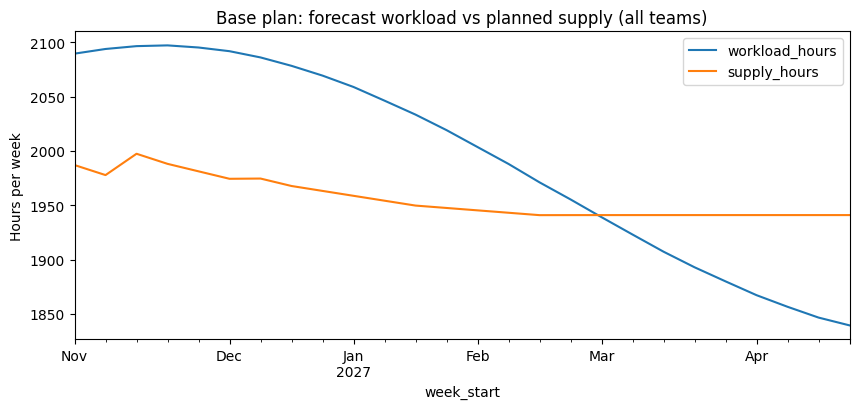

In [7]:
w = base.groupby("week_start")[["workload_hours", "supply_hours"]].sum()
w.plot(figsize=(10, 4), title="Base plan: forecast workload vs planned supply (all teams)")
plt.ylabel("Hours per week"); plt.show()

In [8]:
def summarize(plan, base_plan):
    weekly = plan.groupby("week_no").agg(fte_gap=("fte_gap", "sum"), backlog=("backlog_hours", "sum"),
                                         workload=("workload_hours", "sum"))
    promised = plan["promised_saving"].sum()
    realized = (plan["workload_no_auto"] - plan["workload_hours"]).sum()
    return {
        "peak_fte_gap": round(weekly["fte_gap"].min(), 1),
        "backlog_wk12_hours": round(weekly.loc[12, "backlog"]),
        "backlog_wk12_days": round(weekly.loc[12, "backlog"] / (weekly.loc[12, "workload"] / 5), 1),
        "backlog_wk26_hours": round(weekly.loc[26, "backlog"]),
        "labor_cost_26wk": round(plan["labor_cost"].sum()),
        "labor_cost_change": round(plan["labor_cost"].sum() - base_plan["labor_cost"].sum()),
        "promised_hours_saved": round(promised),
        "realized_hours_saved": round(realized),
        "realization_rate": round(realized / promised, 2) if promised > 0 else None,
    }

SCENARIOS = {
    "Base plan":       ("Current assumptions, backfill leavers", {}),
    "Automation 30%":  ("30% of digital requests auto-filled from week 4", {"automation_pct": 0.30}),
    "New client":      ("+15% volume from week 6", {"volume_change_pct": 0.15}),
    "Attrition spike": ("Attrition doubles for 13 weeks", {"attrition_multiplier": 2.0}),
    "Hiring freeze":   ("No backfill for 12 weeks", {"hiring_freeze_weeks": 12}),
}

plans, summary_rows = [], []
for name, (description, changes) in SCENARIOS.items():
    p = run_plan(**changes)
    plans.append(p.assign(scenario=name))
    summary_rows.append({"scenario": name, "what_changes": description, **summarize(p, base)})

plan_weekly = pd.concat(plans, ignore_index=True)
scenario_summary = pd.DataFrame(summary_rows)
scenario_summary.drop(columns="what_changes")

,scenario,peak_fte_gap,backlog_wk12_hours,backlog_wk12_days,backlog_wk26_hours,labor_cost_26wk,labor_cost_change,promised_hours_saved,realized_hours_saved,realization_rate
0,Base plan,-4.0,2195,5.4,1897,1997686,0,0,0,NaN
1,Automation 30%,-4.0,686,1.9,541,1997686,0,6677,4300,0.64
2,New client,-14.7,4364,9.3,8100,1997686,0,0,0,NaN
3,Attrition spike,-5.9,2794,6.9,3042,1979466,-18220,0,0,NaN
4,Hiring freeze,-4.2,2300,5.7,3027,1928433,-69253,0,0,NaN


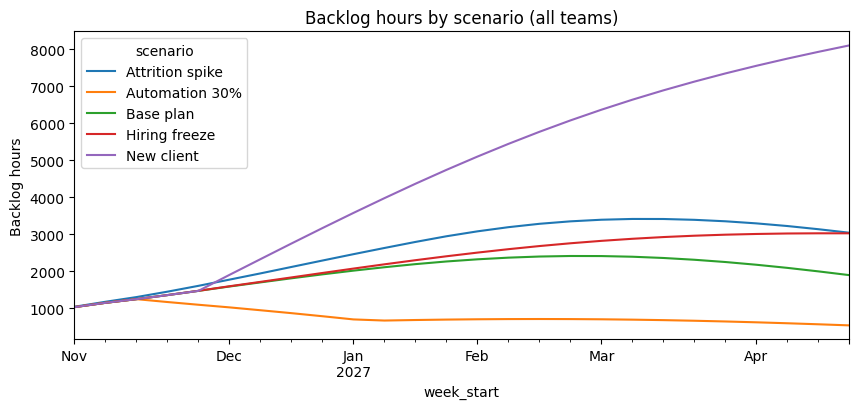

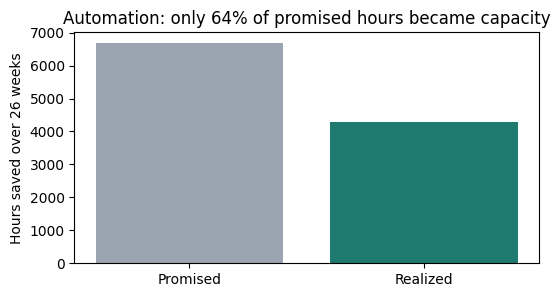

In [9]:
bl = plan_weekly.groupby(["week_start", "scenario"])["backlog_hours"].sum().unstack()
bl.plot(figsize=(10, 4), title="Backlog hours by scenario (all teams)")
plt.ylabel("Backlog hours"); plt.show()

auto = scenario_summary.set_index("scenario").loc["Automation 30%"]
plt.figure(figsize=(6, 3))
plt.bar(["Promised", "Realized"], [auto["promised_hours_saved"], auto["realized_hours_saved"]], color=["#9aa5b1", "#1f7a70"])
plt.title(f"Automation: only {auto['realization_rate']:.0%} of promised hours became capacity")
plt.ylabel("Hours saved over 26 weeks"); plt.show()

In [10]:
def hires_needed(target_days=1.0, max_hires=20, **changes):
    needed = {}
    for team in teams:
        for n in range(max_hires + 1):
            p = run_plan(extra_hires={team: n}, **changes)
            if p[(p["team"] == team) & (p["week_no"] == HORIZON)]["backlog_days"].iloc[0] <= target_days:
                needed[team] = n
                break
        else:
            needed[team] = max_hires
    return needed

options = {
    "Hire only":             {"volume_change_pct": 0.15},
    "Automation 30% + hire": {"volume_change_pct": 0.15, "automation_pct": 0.30},
}
rec_rows = []
for option, changes in options.items():
    hires = hires_needed(**changes)
    s = summarize(run_plan(extra_hires=hires, **changes), base)
    rec_rows.append({"option": option, "total_hires": sum(hires.values()),
                     **{"hires_" + t.split()[0].lower(): n for t, n in hires.items()},
                     "backlog_wk26_hours": s["backlog_wk26_hours"], "labor_cost_change": s["labor_cost_change"]})

recommendation = pd.DataFrame(rec_rows)
recommendation

,option,total_hires,hires_legal,hires_patient,hires_payer,backlog_wk26_hours,labor_cost_change
0,Hire only,18,7,5,6,56,437873
1,Automation 30% + hire,8,2,2,4,19,194610


In [11]:
plan_weekly.round(2).to_sql("plan_weekly", engine, schema="cap", if_exists="replace", index=False)
scenario_summary.to_sql("scenario_summary", engine, schema="cap", if_exists="replace", index=False)
recommendation.to_sql("recommendation", engine, schema="cap", if_exists="replace", index=False)
print("Saved:", len(plan_weekly), "plan rows,", len(scenario_summary), "scenarios,", len(recommendation), "options")

Saved: 390 plan rows, 5 scenarios, 2 options


In [12]:
def run_sql_file(path):
    script = Path(path).read_text()
    batches = [b.strip() for b in re.split(r"^\s*GO\s*$", script, flags=re.MULTILINE | re.IGNORECASE) if b.strip()]
    with engine.begin() as conn:
        for batch in batches:
            conn.execute(text(batch))
    print("Ran", Path(path).name)

run_sql_file(Path("..") / "sql" / "05_reporting.sql")

Ran 05_reporting.sql


In [13]:
def run_sql_file(path):
    script = Path(path).read_text()
    batches = [b.strip() for b in re.split(r"^\s*GO\s*$", script, flags=re.MULTILINE | re.IGNORECASE) if b.strip()]
    with engine.begin() as conn:
        for batch in batches:
            conn.execute(text(batch))
    print("Ran", Path(path).name)

run_sql_file(Path("..") / "sql" / "05_reporting.sql")

Ran 05_reporting.sql


In [14]:
with engine.begin() as conn:
    conn.execute(text("EXEC cap.run_data_checks"))

checks = pd.read_sql("SELECT * FROM cap.latest_checks", engine)
mape = float(pd.read_sql("SELECT mape FROM cap.model_metrics", engine)["mape"][0])
week_loaded = pd.read_sql("SELECT MAX(week_start) AS w FROM clean.requests", engine)["w"][0]
rows_loaded = int(pd.read_sql(text("SELECT COUNT(*) AS n FROM raw.requests WHERE week_start = :w"),
                              engine, params={"w": week_loaded})["n"][0])
passed = int((checks["result"] == "PASS").sum())

run = pd.DataFrame([{
    "run_time": pd.Timestamp.now(), "week_loaded": week_loaded, "rows_loaded": rows_loaded,
    "checks_passed": passed, "checks_total": len(checks), "mape": mape,
    "status": "Success" if passed == len(checks) else "Check failures",
}])
run.to_sql("pipeline_runs", engine, schema="cap", if_exists="append", index=False)

display(checks[["check_name", "result"]])
print(f"Logged run: week {week_loaded}, {passed}/{len(checks)} checks passed, MAPE {mape}%")

,check_name,result
0,Every request type/channel has a handle time,PASS
1,No negative request volumes,PASS
2,No agent leaves before they start,PASS
3,No duplicate agent IDs,PASS
4,Every week has every team in the ledger,PASS
5,Ledger headcount reconciles to the roster,PASS


Logged run: week 2026-10-26, 6/6 checks passed, MAPE 3.4%
